# Figure 3, Figure 4 and Extended Data Figure 9

This notebook computes the figures related to experiments with SpCas9, PpCas9 and AlkaCas9.

In [1]:
import os
import sys
import cv2
import numpy as np
import pandas as pd
import os.path as op
import pickle as pkl
sys.path.append("..")
from Bio.Seq import Seq
import Levenshtein as lev
from Bio import pairwise2
from Bio import SeqIO, motifs
import src.swiper_cli as swiper
import matplotlib.pyplot as plt
import src.convergence_test as convergence
from matplotlib.offsetbox import AnnotationBbox, OffsetImage

/home/drlapki/micromamba/envs/ml-generic/lib/python3.9/site-packages/Bio/pairwise2.py:278: BiopythonDeprecationWarning: Bio.pairwise2 has been deprecated, and we intend to remove it in a future release of Biopython. As an alternative, please consider using Bio.Align.PairwiseAligner as a replacement, and contact the Biopython developers if you still need the Bio.pairwise2 module.
  warnings.warn(


First, we define class for the experimental results:

In [2]:
class F3():

    def __init__(self, proteins, PAMs, n=7, n_value=0.1, directory="../data/interim/wetlab/"):
        """
        Initializes the Figure 3 pipeline for a specific set of proteins and their
        known/expected PAM sequences.

        Args:
            proteins (list of str): Protein names/identifiers (e.g., Cas9 variants).
            PAMs (list of str): Canonical/wild-type PAM sequences for each protein
                                (used as the reference for scoring).
            n (int, optional): PAM candidate length used during classification
                               (passed directly to swiper.classify_all). Defaults to 7.
            n_value (float, optional): Scaling/weighting factor for the convergence score
                                       calculation. Defaults to 0.1.
            directory (str, optional): Root path where trained models are stored.
                                       Defaults to "../data/interim/wetlab/".
        """
        self.proteins = proteins
        self.n = n
        self.n_value = n_value
        self.PAMs = {a: b for a,b in zip(proteins, PAMs)}
        self.dirs = {a: op.join(directory, a) for a in proteins}

    @staticmethod
    def draw_logo(df, fn):
        """
        Generates a sequence logo image from the PAM column of a DataFrame.

        Args:
            df (pandas.DataFrame): Must contain a column named "PAM".
            fn (str): Absolute or relative filepath where the .png logo will be saved.
        """
        swiper.save_fasta("/tmp/swiper.fasta", df["PAM"])
        swiper.make_logo("/tmp/swiper.fasta", fn)
    
    def load_model(self, protein, step):
        """
        Loads a pickled classification model from the disk.

        Each protein and each active learning round has its own trained model.
        These models are the core classifiers used to predict which PAMs are cleaved.

        Args:
            protein (str): Protein identifier.
            step (int or str): Active learning step number.

        Returns:
            object: Deserialized model.
        """
        with open(op.join(self.dirs[protein], "final", "model_"+str(step)+".pkl"), "rb") as ih:
            model = pkl.load(ih)
        return(model)

    def screen(self, protein, step):
        """
        Runs the full PAM classification screen for a given protein/step.

        This replicates the computational screening that underlies the experimental
        data shown in Figure 3. It uses the trained model to score/evaluate all
        possible PAM sequences.

        Args:
            protein (str): Protein identifier.
            step (int or str): Active learning step.

        Returns:
            pandas.DataFrame: Complete classification table with predictions
                              (includes a 'Y_class' column marking '+' for cleaved).
        """
        model = self.load_model(protein, step)
        df, _ = swiper.classify_all(model, n=self.n)
        return(df)

    def point(self, protein, step, fnmask):
        """
        The main method for generating a single data point for Figure 3.

        This method executes the full workflow in one call:
        1. Screens all PAMs.
        2. Isolates only the "cleaved" (positive) predictions.
        3. Derives the degenerate consensus motif.
        4. Draws the sequence logo and saves it as a PNG.
        5. Computes a convergence score comparing the derived motif to the reference PAM.

        Args:
            protein (str): Protein identifier.
            step (int or str): The active learning step.
            fnmask (str): Base directory or filename prefix for the output PNG.
                          The final path will be: {fnmask}/{protein}.{step}.png

        Returns:
            tuple: (consensus_sequence, convergence_score)
                - consensus (str): The degenerate motif shown in the logo.
                - score (float): Quantitative measure of how well the predicted
                  motif matches the known reference PAM (used for the bar plots/scatter
                  panels in Figure 3).
        """
        df = self.screen(protein, step)
        cleaved = df[df["Y_class"] == "+"]
        consensus = convergence.get_consensus(cleaved["PAM"].values)
        F3.draw_logo(cleaved, op.join(fnmask, protein+"."+str(step)+".png"))
        score = convergence.consensus_score(self.PAMs[protein], consensus, self.n_value)
        return(consensus, score)

And a helper function for plotting sequence logos:

In [3]:
def add_image_overlay(img, ax, zoom, xy, xytext, arrowprops, **kwargs):
    """
    Add an image overlay annotation to a matplotlib axes.
    
    Parameters:
    ----------
    ax : matplotlib.axes.Axes
        The matplotlib axes instance where the annotation will be added
    x, y : float
        Coordinates of the bottom-left corner of the image
    width, height : float
        Dimensions of the image in data coordinates
    xy : tuple of float, optional
        Target point coordinates for the arrow (default: center of image)
    kwargs : dict
        Additional keyword arguments passed to AnnotationBbox
        
    Returns:
    -------
    AnnotationBbox
        The created annotation box instance
    """
    # Create sample image data
    im = OffsetImage(img, zoom=zoom)
    im.image.axes = ax
        
    # Create and add annotation
    ab = AnnotationBbox(im, xy, xytext,
                       #xybox=(-50., 50.),
                       xycoords='data',
                       boxcoords="offset points",
                       pad=0.3,
                       arrowprops=arrowprops,
                       **kwargs)
    ax.add_artist(ab)
    
    return ab

The generation of synthetic data for the null hypothesis mirrors the experimental
    workflow in which we observe a candidate PAM sequence from one experimental round
    and then a candidate from the next experimental round. First, a set of “left-hand”
    k-mers of given k is produced. Then, each of these strings is randomly perturbed to
    generate the corresponding “right-hand” counterpart – this gives similar strings with
    varying degrees of similarity (measured in terms of consensus score) to the “left-hand” ones.

In [4]:
lefts = convergence.generate_H0(10000, lags=[1,2,3,4,5], alphabet=convergence.IUPAC_DNA_no_gap)
rights = convergence.make_rights(lefts, alphabet=convergence.IUPAC_DNA_no_gap)

This procedure gives us a set of sequence pairs that
vary in similarity but have no convergence in terms of PAM consensus score.

And we make intermediate folders for sequence logos:

In [5]:
os.makedirs("F3", exist_ok=True)
os.makedirs("F4", exist_ok=True)

# Figure 3 -- Active learning with Switching Round protocol faithfully reproduces known PAM sequences.

Load the experimental data:

In [6]:
f3 = F3(["SpCas9", "PpCas9"], ["NGGNNNN", "NNNNRTN"], 7, 0.1, "../data/interim/wetlab/")

In [7]:
spcas9  = np.array([f3.point("SpCas9", a, "./F3/") for a in np.arange(1,11)])

/home/drlapki/Works/swiper/notebooks/../src/swiper_cli.py:273: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["Y_class"] = y_full_class
/home/drlapki/Works/swiper/notebooks/../src/swiper_cli.py:273: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["Y_class"] = y_full_class
/home/drlapki/Works/swiper/notebooks/../src/swiper_cli.py:273: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the d

In [8]:
spcas9

array([['NGNNNNN', '2.4000000000000004'],
       ['NGNNNNN', '2.4000000000000004'],
       ['NGGNNNN', '3.4000000000000004'],
       ['NGGNNNN', '3.4000000000000004'],
       ['NGGNNNN', '3.4000000000000004'],
       ['NGGNNNN', '3.4000000000000004'],
       ['NGGNNNN', '3.4000000000000004'],
       ['NGGNNNN', '3.4000000000000004'],
       ['NGGNNNN', '3.4000000000000004'],
       ['NGGNNNN', '3.4000000000000004']], dtype='<U32')

Compute convergence statistics for SpCas9:

In [9]:
spcas9_history_stat, spcas9_history_H0, spcas9_bvs, spcas9_st, spcas9_sigs = convergence.run_test(
    spcas9, (lefts, rights), convergence.statistic, pval_threshold=0.05
)

In [10]:
ppcas9  = np.array([f3.point("PpCas9", a, "./F3/") for a in np.arange(1,11)])

/home/drlapki/Works/swiper/notebooks/../src/swiper_cli.py:273: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["Y_class"] = y_full_class
/home/drlapki/Works/swiper/notebooks/../src/swiper_cli.py:273: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["Y_class"] = y_full_class
/home/drlapki/Works/swiper/notebooks/../src/swiper_cli.py:273: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the d

In [11]:
ppcas9

array([['KNRCGTN', '2.1'],
       ['GNNNGTC', '4'],
       ['GRNCRTY', '3'],
       ['GNNCRTN', '4.1'],
       ['GNNCRTN', '4.1'],
       ['NNNCRTN', '5.1'],
       ['NNNNRTN', '6.1'],
       ['NNNNRTN', '6.1'],
       ['NNNNRTN', '6.1'],
       ['NNNNRTN', '6.1']], dtype='<U32')

Compute convergence statistics for PpCas9:

In [12]:
ppcas9_history_stat, ppcas9_history_H0, ppcas9_bvs, ppcas9_st, ppcas9_sigs = convergence.run_test(
    ppcas9, (lefts, rights), convergence.statistic, pval_threshold=0.05
)

Compute p-values:

In [13]:
pairs = [[a, a+1] for a in np.arange(9)]
spcas9_pvalues_X = np.mean(np.array(pairs) + 1, 1)-0.4

In [14]:
spcas9_pvalues = np.array([convergence.compute_pvalue(a, spcas9_history_H0) for a in spcas9_history_stat])
ppcas9_pvalues = np.array([convergence.compute_pvalue(a, ppcas9_history_H0) for a in ppcas9_history_stat])

Plot the figure:

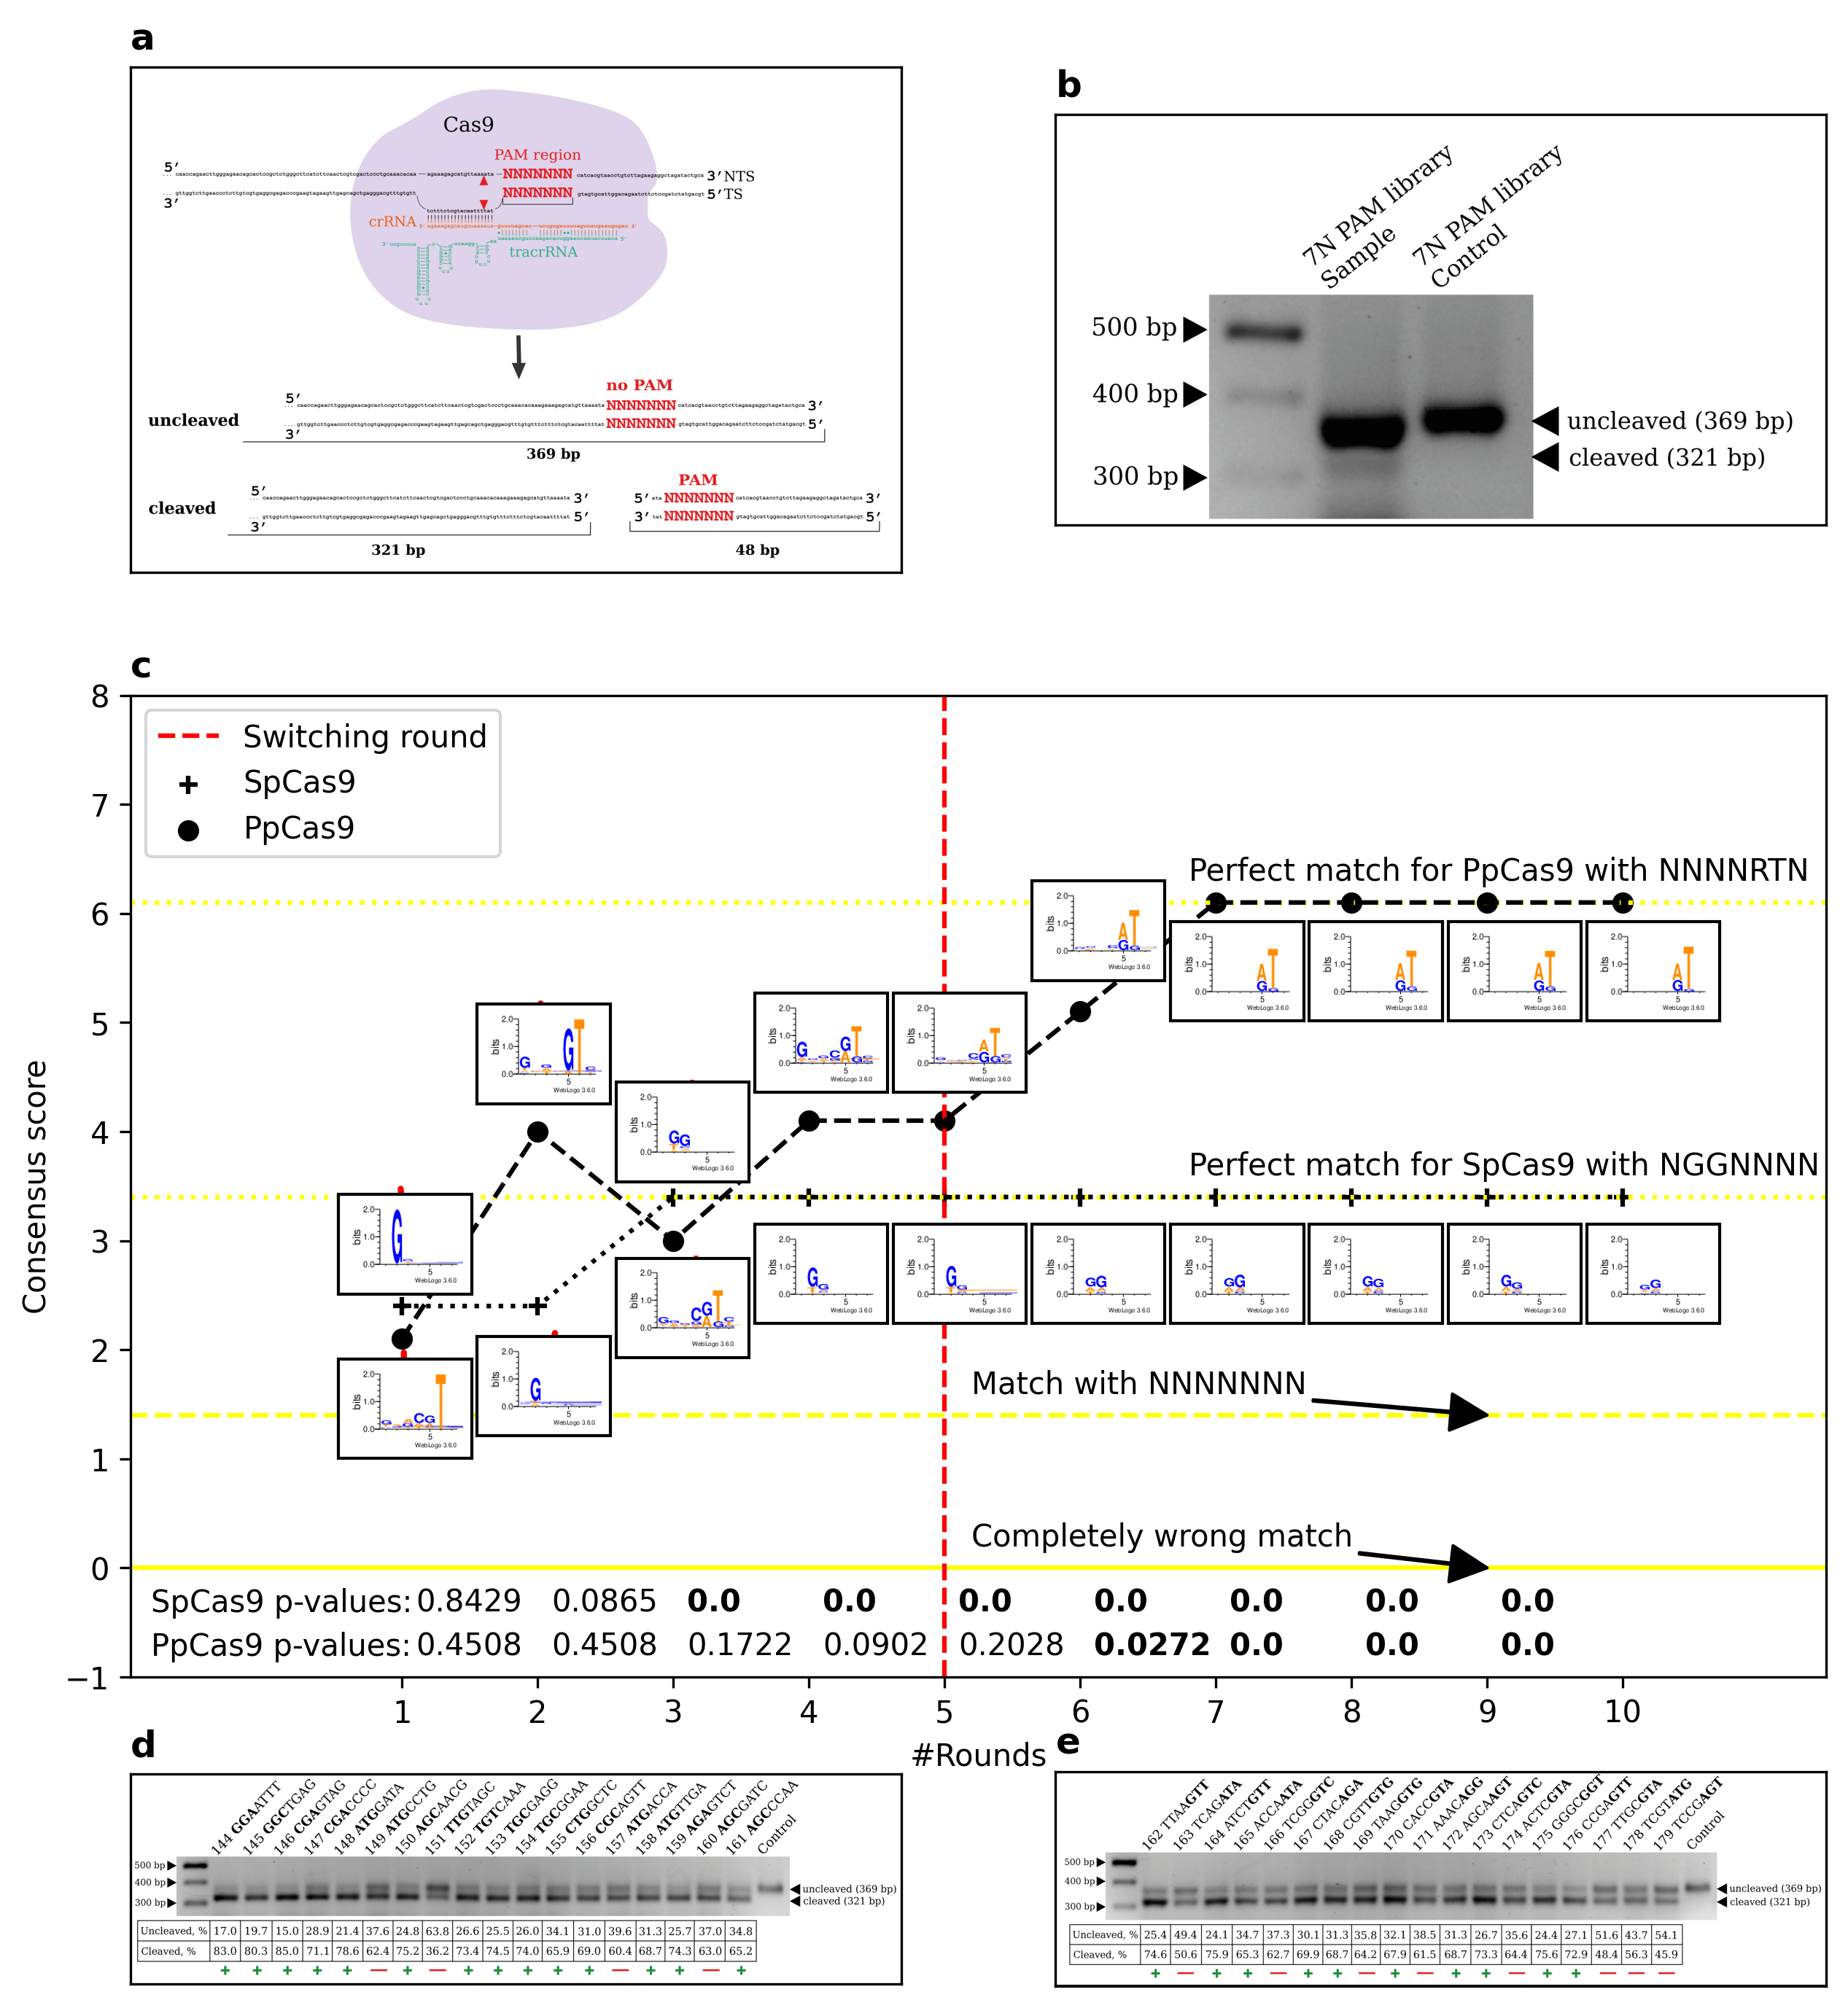

In [15]:
plt.rcParams["figure.figsize"] = 10,12
plt.rcParams["figure.dpi"] = 300

perfect_spcas9 = convergence.consensus_score(f3.PAMs["SpCas9"], f3.PAMs["SpCas9"])
perfect_ppcas9 = convergence.consensus_score(f3.PAMs["PpCas9"], f3.PAMs["PpCas9"])
unidentified = convergence.consensus_score(f3.PAMs["SpCas9"], "NNNNNNN")
wrong = convergence.consensus_score("NNNNNNN", "AAAAAAA")

#fig, ax = plt.subplots()
fig = plt.figure()
fig.tight_layout()
axd = fig.subplot_mosaic(
    """
    AB
    AB
    CC
    CC
    CC
    DE
    """
)

panel_a = cv2.cvtColor(cv2.imread("./F3/Cas9_in_vitro_test_scheme.png"), cv2.COLOR_BGR2RGB)
axd["A"].imshow(panel_a)
axd["A"].set_xticks([])
axd["A"].set_yticks([])
axd["A"].set_title("a", loc="left", weight="bold")


panel_b = cv2.cvtColor(cv2.imread("./F3/AlkaCas9_7N_PAM_lib.png"), cv2.COLOR_BGR2RGB)
axd["B"].imshow(panel_b)
axd["B"].set_xticks([])
axd["B"].set_yticks([])
axd["B"].set_title("b", loc="left", weight="bold")


axd["C"].set_ylim((wrong-1, 8))
axd["C"].set_xlim((0,11))

axd["C"].axhline(y=unidentified, color="yellow", linestyle="dashed")
axd["C"].axhline(y=perfect_spcas9, color="yellow", linestyle="dotted")
axd["C"].axhline(y=perfect_ppcas9, color="yellow", linestyle="dotted")
axd["C"].axhline(y=wrong, color="yellow")

axd["C"].axvline(x=5, color="red", linestyle="dashed", label="Switching round")


axd["C"].scatter(np.arange(1,11), spcas9.T[1].astype(np.float64), color="black", marker="+", label="SpCas9")
axd["C"].plot(np.arange(1,11), spcas9.T[1].astype(np.float64), color="black", linestyle="dotted")
axd["C"].scatter(np.arange(1,11), ppcas9.T[1].astype(np.float64), color="black", marker="o", label="PpCas9")
axd["C"].plot(np.arange(1,11), ppcas9.T[1].astype(np.float64), color="black", linestyle="dashed")

axd["C"].set_xlabel("#Rounds")
axd["C"].set_ylabel("Consensus score")

axd["C"].annotate(
    xy=(10, perfect_spcas9),
   # arrowprops=dict(facecolor='black', shrink=1, width=0.5),
    xytext=(6.8, perfect_spcas9+0.2), 
    text="Perfect match for SpCas9 with "+f3.PAMs["SpCas9"]
)

axd["C"].annotate(
    xy=(2, perfect_ppcas9),
  #  arrowprops=dict(facecolor='black', shrink=1, width=0.5),
    xytext=(6.8, perfect_ppcas9+0.2), 
    text="Perfect match for PpCas9 with "+f3.PAMs["PpCas9"]
)

axd["C"].annotate(
    xy=(9, unidentified),
    arrowprops=dict(facecolor='black', shrink=1, width=0.5),
    xytext=(5.2, unidentified+0.2), 
    text="Match with NNNNNNN",
)

axd["C"].annotate(
    xy=(9, 0),
    xytext=(5.2, 0.2), 
    text="Completely wrong match",
    arrowprops=dict(facecolor='black', shrink=1, width=0.5)
)

axd["C"].set_title("c", loc="left", weight="bold")
axd["C"].legend(loc="upper left")
axd["C"].set_xticks(np.arange(1,11))

arrowprops = {
    'arrowstyle': '->',      # Double-headed arrow
    'color': 'red',
    'lw': 2,
    'shrinkA': 0,
    'shrinkB': 0,
    'connectionstyle': 'arc3' # Curved connection
}

for a,b,c in zip(np.arange(1,11), spcas9.T[1].astype(np.float64), [-0.5,0.8,-0.5,0.8,0.8,0.8,0.8,0.8,0.8,0.8]):
    cur_img = cv2.cvtColor(cv2.imread("./F3/SpCas9."+str(a)+".png"), cv2.COLOR_BGR2RGB)
    add_image_overlay(cur_img, axd["C"], zoom=0.25, xy=(a,b-c), xytext=(a,b), arrowprops=arrowprops)#, arrowprops=dict(facecolor='black'))

for a,b,c in zip(np.arange(1,11), ppcas9.T[1].astype(np.float64), np.array([0.7,-0.6,0.7,-0.6,-0.6,-0.6,0.8,0.8,0.8,0.8])):
    cur_img = cv2.cvtColor(cv2.imread("./F3/PpCas9."+str(a)+".png"), cv2.COLOR_BGR2RGB)
    add_image_overlay(cur_img, axd["C"], zoom=0.25, xy=(a,b-c), xytext=(a,b), arrowprops=arrowprops)#, arrowprops=dict(facecolor='black'))

for a,b in zip(spcas9_pvalues_X, spcas9_pvalues):
    axd["C"].annotate(xy=(a, -0.4), text=b, weight="bold" if b <= 0.05 else "normal")
for a,b in zip(spcas9_pvalues_X, ppcas9_pvalues):
    axd["C"].annotate(xy=(a, -0.8), text=b, weight="bold" if b <= 0.05 else "normal")

axd["C"].annotate(xy=(-0.85, -0.4), text="SpCas9 p-values:")
axd["C"].annotate(xy=(-0.85, -0.8), text="PpCas9 p-values:")

axd["C"].set_xlim((-1, 11.5))

panel_d = cv2.cvtColor(cv2.imread("./F3/SpCas9_set_8.png"), cv2.COLOR_BGR2RGB)
axd["D"].imshow(panel_d)
axd["D"].set_xticks([])
axd["D"].set_yticks([])
axd["D"].set_title("d", loc="left", weight="bold")

panel_e = cv2.cvtColor(cv2.imread("./F3/PpCas9_set_8.png"), cv2.COLOR_BGR2RGB)
axd["E"].imshow(panel_e)
axd["E"].set_xticks([])
axd["E"].set_yticks([])
axd["E"].set_title("e", loc="left", weight="bold")

plt.savefig("Figure3.png", bbox_inches='tight', pad_inches=0)

plt.show()

# Figure 4 -- Active learning with Switching Round protocol discovers PAM for a novel Cas9 ortholog.

Load the data:

In [16]:
f4 = F3(["AlkaCas9"], ["NNNNNNN"], 7, 0.1, "../data/interim/wetlab/")

In [17]:
alkacas9  = np.array([f4.point("AlkaCas9", a, "./F4/") for a in np.arange(1,11)])

/home/drlapki/Works/swiper/notebooks/../src/swiper_cli.py:273: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["Y_class"] = y_full_class
/home/drlapki/Works/swiper/notebooks/../src/swiper_cli.py:273: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["Y_class"] = y_full_class
/home/drlapki/Works/swiper/notebooks/../src/swiper_cli.py:273: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the d

In [18]:
alkacas9

array([['AGGAGTC', '0'],
       ['NNGANAN', '4'],
       ['TNGANAN', '3'],
       ['TNGANAN', '3'],
       ['TNGANAN', '3'],
       ['NNGANNN', '5'],
       ['NNGAVNN', '4'],
       ['NNGAVNN', '4'],
       ['NNGAVNN', '4'],
       ['NNGAVNN', '4']], dtype='<U21')

Compute the convergence statistics for AlkaCas9:

In [19]:
alkacas9_history_stat, alkacas9_history_H0, alkacas9_bvs, alkacas9_st, alkacas9_sigs = convergence.run_test(
    alkacas9, (lefts, rights), convergence.statistic, pval_threshold=0.05
)

Compute p-values:

In [20]:
alkacas9_pvalues = np.array([convergence.compute_pvalue(a, alkacas9_history_H0) for a in alkacas9_history_stat])

We expect that the final consensus would contain some Ns, but would not match NNNNNNN completely;
therefore, unlike Figure 3c, for ease of visualization, we arrange the experimental
results along the consensus score computed against NNNNNNN.

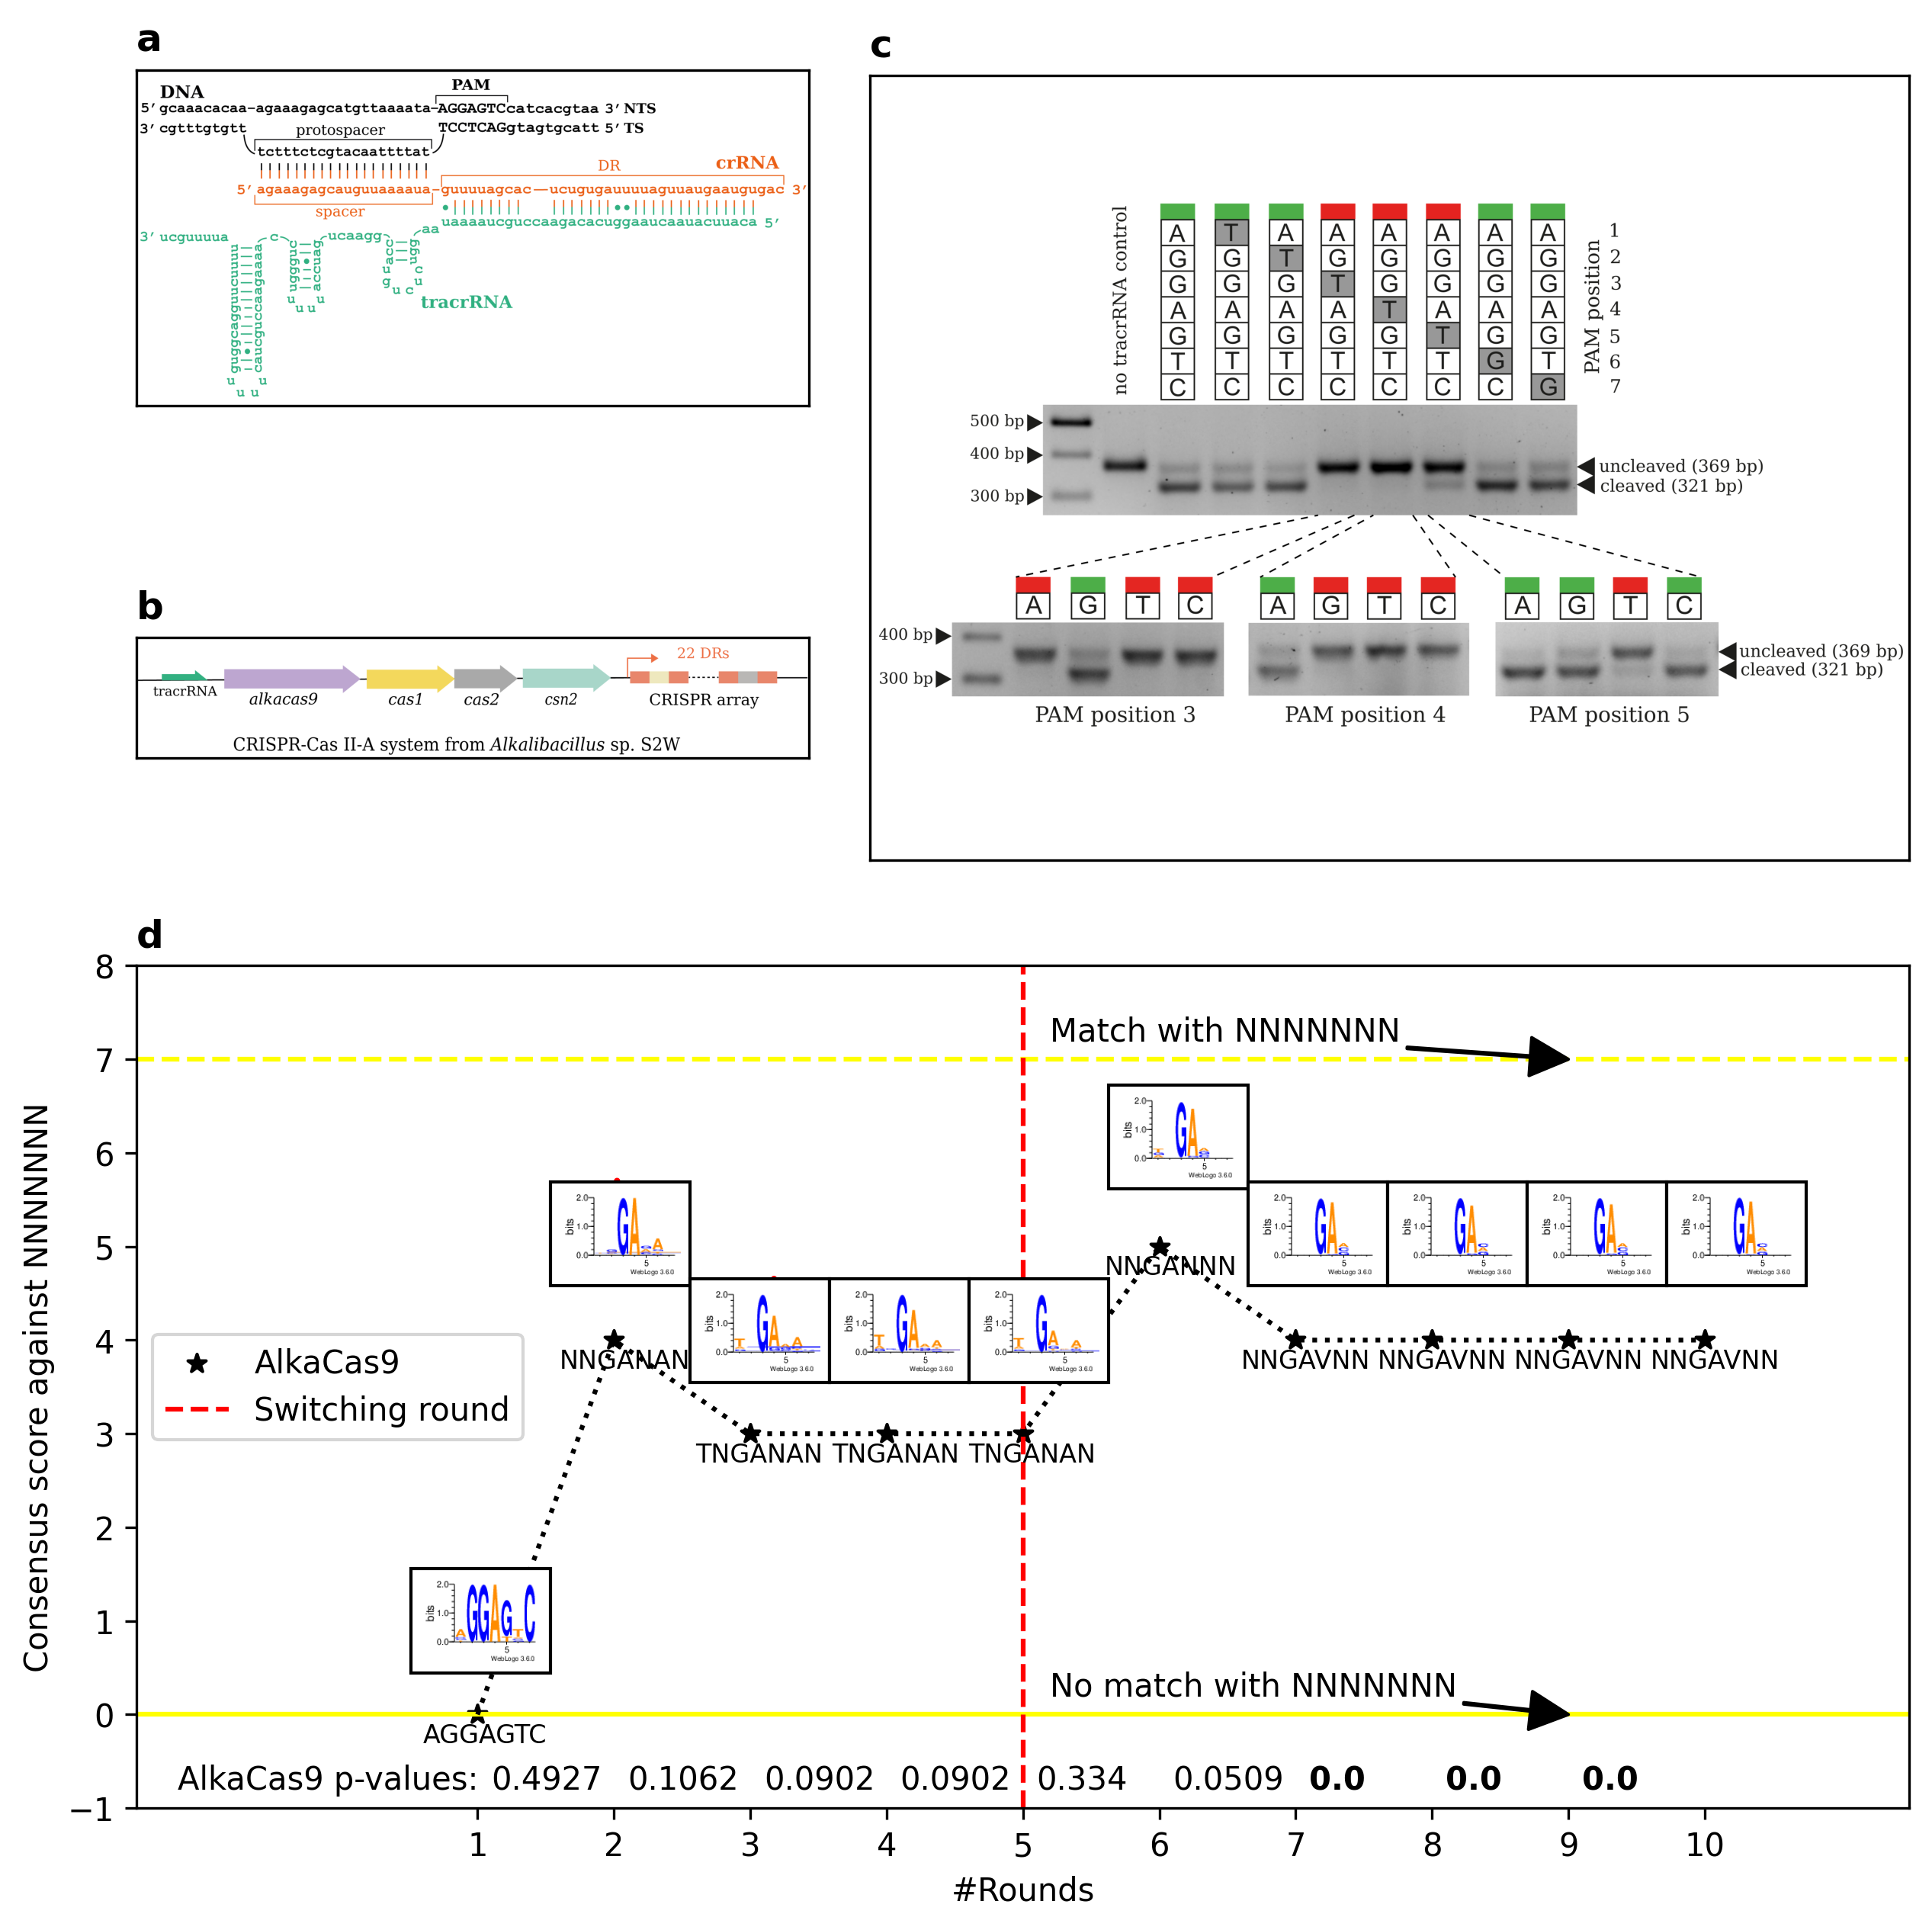

In [21]:
plt.rcParams["figure.figsize"] = 10, 10
plt.rcParams["figure.dpi"] = 300

#perfect_spcas9 = f3.consensus_score(f3.PAMs["SpCas9"], f3.PAMs["SpCas9"])
#perfect_ppcas9 = f3.consensus_score(f3.PAMs["PpCas9"], f3.PAMs["PpCas9"])
unidentified = convergence.consensus_score(f4.PAMs["AlkaCas9"], "NNNNNNN")
wrong = convergence.consensus_score("NNNNNNN", "AAAAAAA")

#fig, ax = plt.subplots()
fig = plt.figure()#layout="tight")
fig.tight_layout()
axd = fig.subplot_mosaic(
    """
    AACCC
    BBCCC
    DDDDD
    DDDDD
    """
)

panel_a = cv2.cvtColor(cv2.imread("./F4/AlkaCas9_RNAs.png"), cv2.COLOR_BGR2RGB)
axd["A"].imshow(panel_a)
axd["A"].set_xticks([])
axd["A"].set_yticks([])
axd["A"].set_title("a", loc="left", weight="bold")

panel_b = cv2.cvtColor(cv2.imread("./F4/AlkaCas_CRISPR_locus.png"), cv2.COLOR_BGR2RGB)
axd["B"].imshow(panel_b)
axd["B"].set_xticks([])
axd["B"].set_yticks([])
axd["B"].set_title("b", loc="left", weight="bold")

axd["D"].set_ylim((wrong-1, 8))
axd["D"].set_xlim((0,11))

axd["D"].axhline(y=unidentified, color="yellow", linestyle="dashed")
axd["D"].axhline(y=wrong, color="yellow")

axd["D"].scatter(np.arange(1,11), alkacas9.T[1].astype(np.float64), color="black", marker="*", label="AlkaCas9")
axd["D"].plot(np.arange(1,11), alkacas9.T[1].astype(np.float64), color="black", linestyle="dotted")

axd["D"].set_xlabel("#Rounds")
axd["D"].set_ylabel("Consensus score against NNNNNNN")

axd["D"].annotate(
    xy=(9, unidentified),
    arrowprops=dict(facecolor='black', shrink=1, width=0.5),
    xytext=(5.2, unidentified+0.2), 
    text="Match with NNNNNNN",
)

axd["D"].axvline(x=5, color="red", linestyle="dashed", label="Switching round")

axd["D"].annotate(
    xy=(9, 0),
    xytext=(5.2, 0.2), 
    text="No match with NNNNNNN",
    arrowprops=dict(facecolor='black', shrink=1, width=0.5)
)

axd["D"].set_title("d", loc="left", weight="bold")
axd["D"].legend(loc="best")
axd["D"].set_xticks(np.arange(1,11))

arrowprops = {
    'arrowstyle': '->',      # Double-headed arrow
    'color': 'red',
    'lw': 2,
    'shrinkA': 0,
    'shrinkB': 0,
    'connectionstyle': 'arc3' # Curved connection
}

for a,b,c in zip(np.arange(1,11), alkacas9.T[1].astype(np.float64), [1,1,1,1,1,1,1,1,1,1]):
    cur_img = cv2.cvtColor(cv2.imread("./F4/AlkaCas9."+str(a)+".png"), cv2.COLOR_BGR2RGB)
    add_image_overlay(cur_img, axd["D"], zoom=0.25, xy=(a,b+c), xytext=(a,b), arrowprops=arrowprops)#, arrowprops=dict(facecolor='black'))
    axd["D"].annotate(text=alkacas9.T[0][a-1], xy=(a-0.4,b-c*0.3), fontsize=8)

for a,b in zip(spcas9_pvalues_X, alkacas9_pvalues):
    axd["D"].annotate(xy=(a, -0.8), text=b, weight="bold" if b <= 0.05 else "normal")
axd["D"].annotate(xy=(-1.2, -0.8), text="AlkaCas9 p-values:")
axd["D"].set_xlim((-1.5, 11.5))

panel_d = cv2.cvtColor(cv2.imread("./F4/AlkaCas9_PAM_check.png"), cv2.COLOR_BGR2RGB)
axd["C"].imshow(panel_d)
axd["C"].set_xticks([])
axd["C"].set_yticks([])
axd["C"].set_title("c", loc="left", weight="bold")

plt.savefig("Figure4.png", bbox_inches='tight', pad_inches=0)

plt.show()

# Extended Data Figure 9 -- statistical tests for convergence of SpCas9, PpCas9 and AlkaCas9;

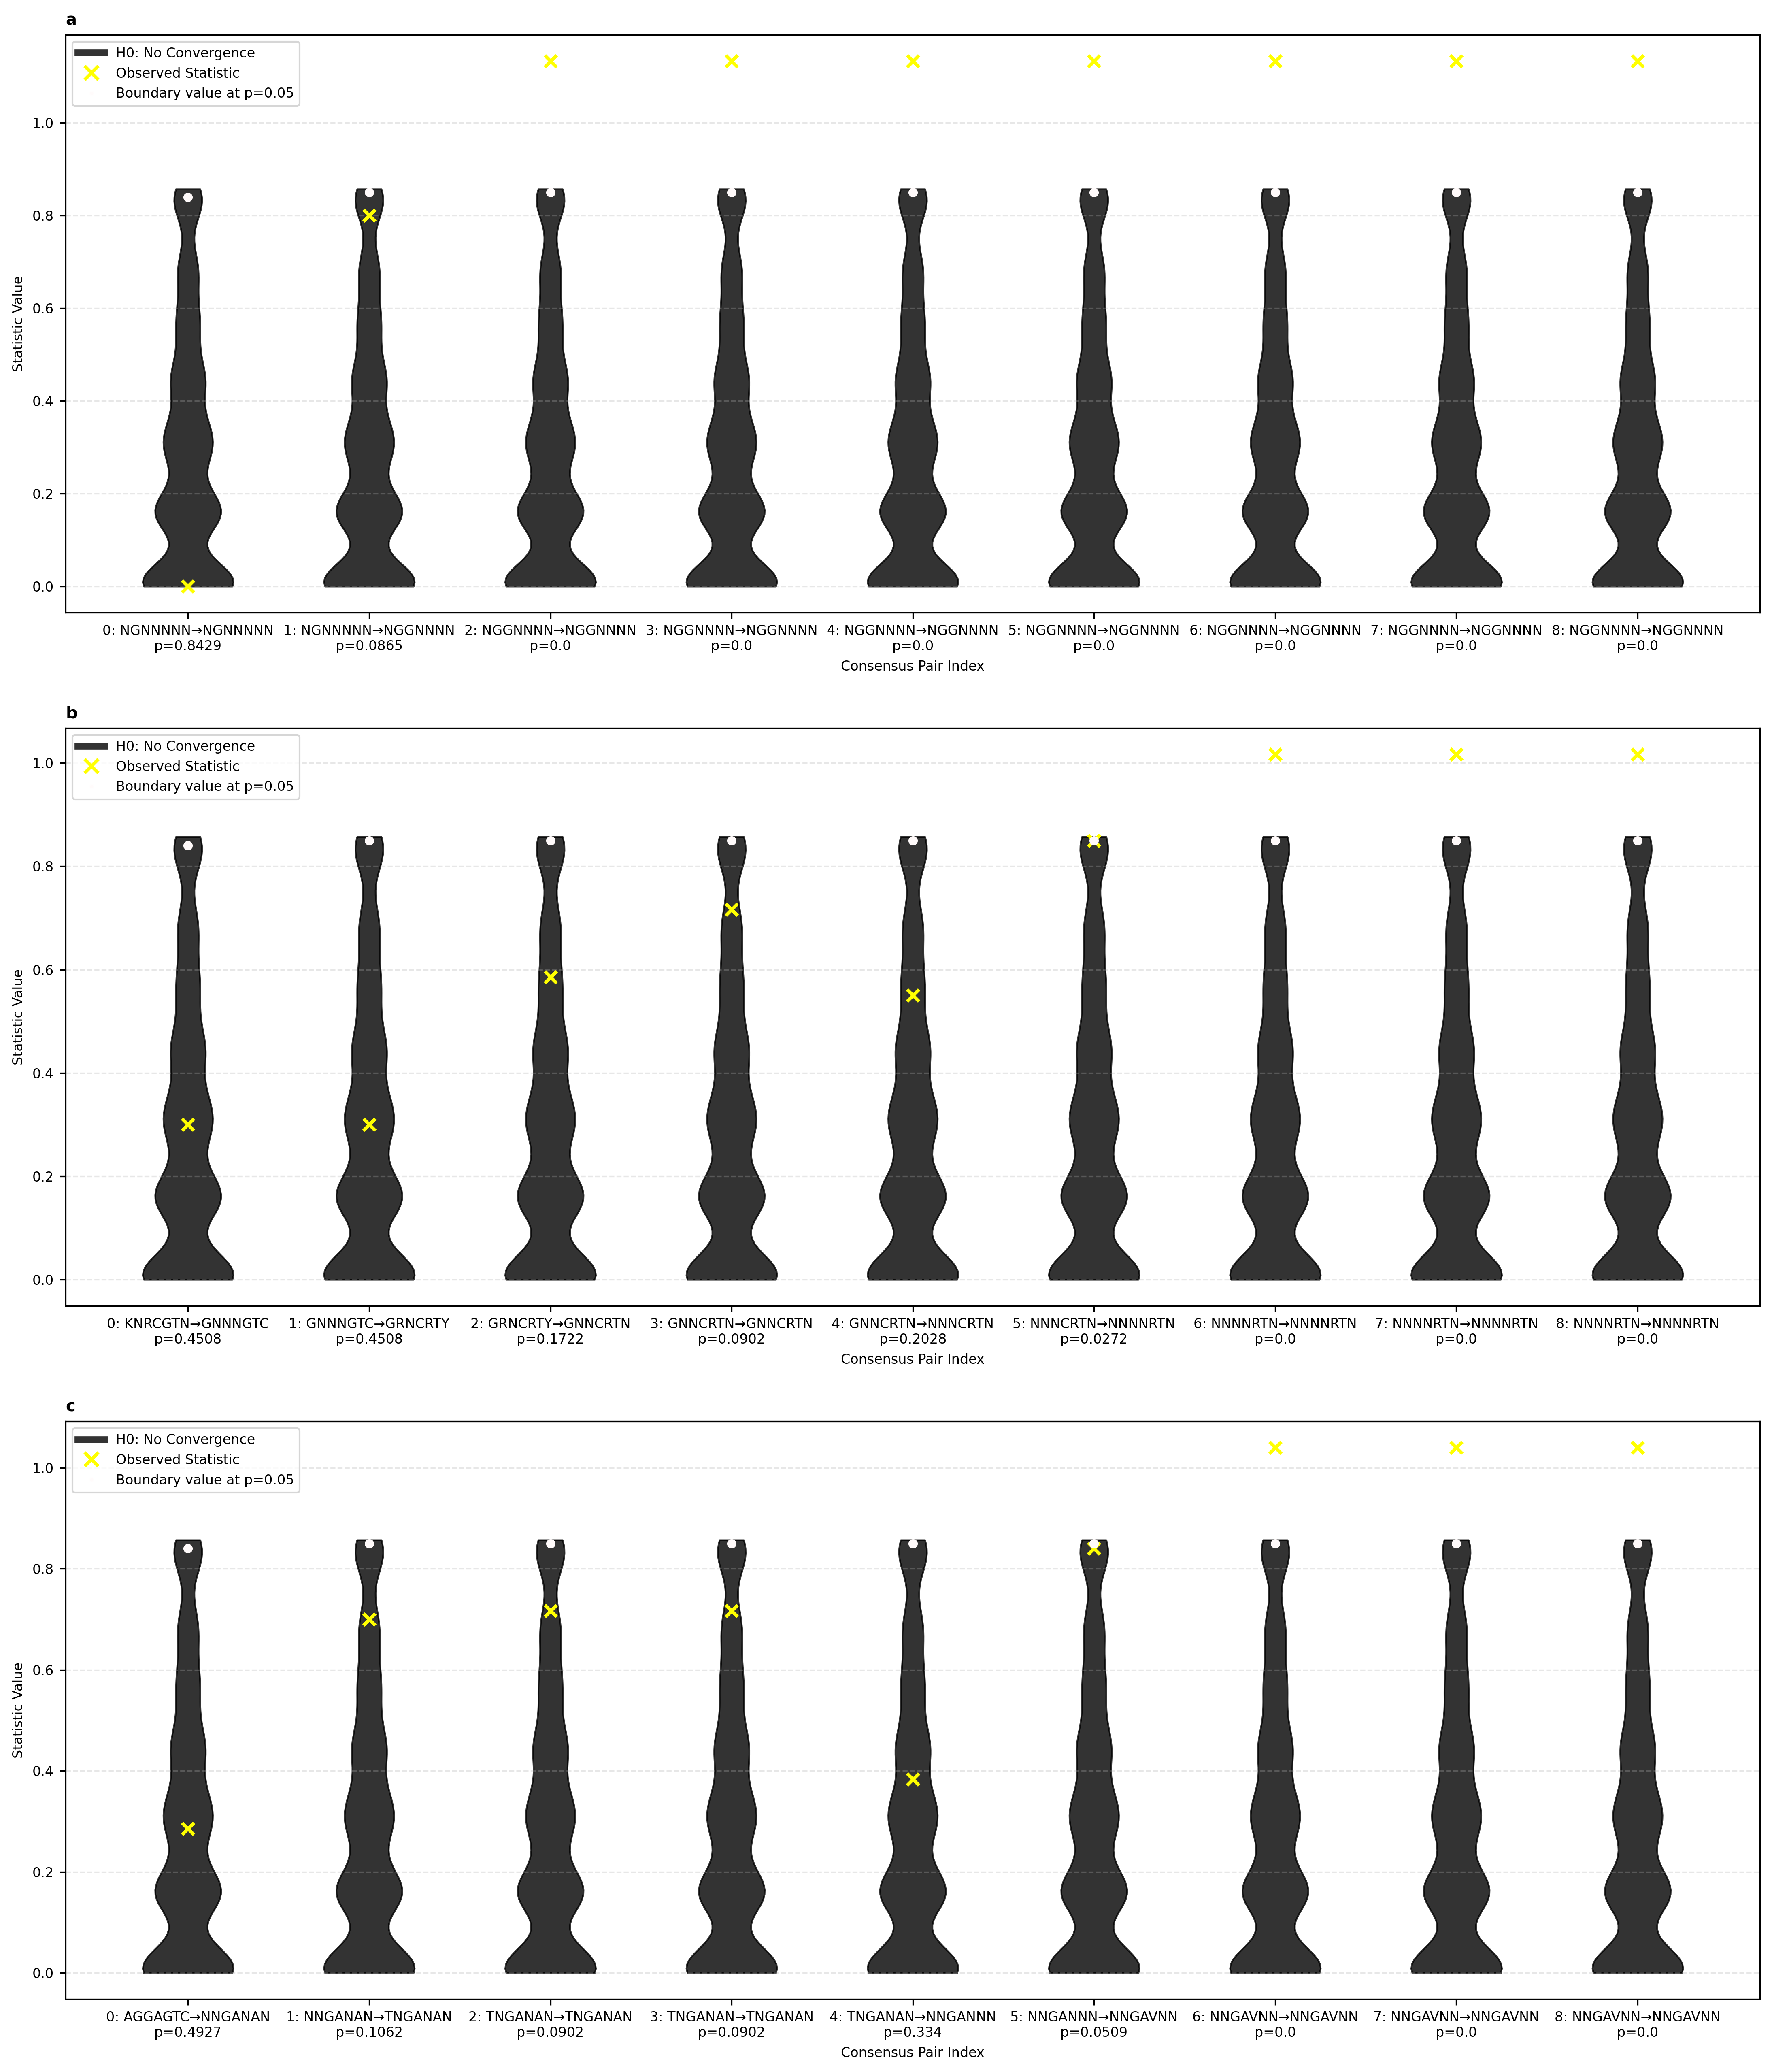

In [22]:
plt.rcParams["figure.figsize"] = 18, 21
plt.rcParams["figure.dpi"] = 300
plt.rcParams["font.size"] = 8

fig = plt.figure()#layout="tight")
fig.tight_layout()
axd = fig.subplot_mosaic(
    """
    AAA
    BBB
    CCC
    """
)

axd["A"].set_title("a", loc="left", weight="bold")
axd["B"].set_title("b", loc="left", weight="bold")
axd["C"].set_title("c", loc="left", weight="bold")
#axd["A"].set_title("Statistical test for convergence of active learning-derived PAM consensus: SpCas9")
convergence.plot_test_violins(spcas9, spcas9_history_stat, spcas9_history_H0, spcas9_bvs, axd["A"], 0.05, location="best", rotation=0)
#axd["B"].set_title("Statistical test for convergence of active learning-derived PAM consensus: PpCas9")
convergence.plot_test_violins(ppcas9, ppcas9_history_stat, ppcas9_history_H0, ppcas9_bvs, axd["B"], 0.05, location="best", rotation=0)
#axd["C"].set_title("Statistical test for convergence of active learning-derived PAM consensus: AlkaCas9")
convergence.plot_test_violins(alkacas9, alkacas9_history_stat, alkacas9_history_H0, alkacas9_bvs, axd["C"], 0.05, location="best", rotation=0)

plt.savefig("EDF9.png", bbox_inches='tight', pad_inches=0)

plt.show()